# Diabetic Retinopathy Grading — Upgraded Pipeline (PyTorch + timm)

Upgrades over the reference notebooks:
- Preprocessing (crop + Ben Graham enhancement) is **actually used** for training
- **Pretrained** EfficientNetV2 backbone (transfer learning) instead of a ResNet trained from scratch
- Stratified train/val/test split, balanced sampling, proper augmentation
- **Ordinal regression** + threshold optimisation, evaluated with **Quadratic Weighted Kappa**
- Test-time augmentation, confusion matrix, per-class report
- **Grad-CAM** explainability and a **Gradio** demo app

**Run on Kaggle (free GPU):** New Notebook → Add Data → search *APTOS 2019 Blindness Detection* → Accelerator: GPU T4 → Internet: On → Run All.
Your own folder layouts also work: `train.csv + images`, or `train/<class_name>/*.png`.
If no dataset is found, a small **synthetic** dataset is generated so you can verify the code runs (results are meaningless in that case).

In [1]:
import importlib, subprocess, sys
for pkg, mod in [("timm","timm"),("albumentations","albumentations"),("opencv-python-headless","cv2"),("gradio","gradio")]:
    if importlib.util.find_spec(mod) is None:
        subprocess.run([sys.executable,"-m","pip","install","-q",pkg])

In [2]:
%%writefile dr_utils.py
"""Shared helpers (used by the notebook AND the Gradio app so preprocessing is identical)."""
import cv2, numpy as np, torch

GRADES = ["0 - No DR", "1 - Mild", "2 - Moderate", "3 - Severe", "4 - Proliferative"]
MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
STD  = np.array([0.229, 0.224, 0.225], dtype=np.float32)

def crop_black(img, tol=7):
    m = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) > tol
    if not m.any():
        return img
    r, c = np.where(m.any(1))[0], np.where(m.any(0))[0]
    return img[r[0]:r[-1] + 1, c[0]:c[-1] + 1]

def pad_square(img):
    h, w = img.shape[:2]; s = max(h, w)
    t, l = (s - h) // 2, (s - w) // 2
    return cv2.copyMakeBorder(img, t, s - h - t, l, s - w - l, cv2.BORDER_CONSTANT, value=0)

def preprocess_image(img_bgr, size=384, ben=True):
    """Crop black borders -> square -> resize -> Ben Graham contrast enhancement -> circular mask. Returns RGB uint8."""
    img = cv2.resize(pad_square(crop_black(img_bgr)), (size, size), interpolation=cv2.INTER_AREA)
    if ben:
        img = cv2.addWeighted(img, 4, cv2.GaussianBlur(img, (0, 0), size / 30), -4, 128)
    mask = np.zeros((size, size), np.uint8)
    cv2.circle(mask, (size // 2, size // 2), size // 2, 1, -1)
    img = cv2.bitwise_and(img, img, mask=mask)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

def to_tensor(rgb_uint8):
    x = (rgb_uint8.astype(np.float32) / 255.0 - MEAN) / STD
    return torch.from_numpy(x.transpose(2, 0, 1)).unsqueeze(0)

def apply_thresholds(p, t):
    return np.digitize(p, t)

def gradcam(model, x, device):
    """Grad-CAM on the last feature map of any timm model. x: (1,3,H,W). Returns heatmap in [0,1] (H,W)."""
    model.eval()
    x = x.to(device)
    with torch.enable_grad():
        feats = model.forward_features(x)
        feats.retain_grad()
        out = model.forward_head(feats)
        model.zero_grad()
        out.sum().backward()
    w = feats.grad.mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((w * feats).sum(1, keepdim=True))
    cam = torch.nn.functional.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
    cam = cam - cam.min()
    cam = cam / (cam.max() + 1e-8)
    return cam.detach().cpu().numpy(), float(out.item())

def overlay(rgb, cam, alpha=0.45):
    heat = cv2.applyColorMap((cam * 255).astype(np.uint8), cv2.COLORMAP_JET)
    heat = cv2.cvtColor(heat, cv2.COLOR_BGR2RGB)
    return (rgb * (1 - alpha) + heat * alpha).astype(np.uint8)

Writing dr_utils.py


In [3]:
import os, glob, random, time, warnings
from pathlib import Path
import numpy as np, pandas as pd, cv2, torch, torch.nn as nn
import matplotlib.pyplot as plt, seaborn as sns
import timm, albumentations as A
from albumentations.pytorch import ToTensorV2
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.model_selection import train_test_split
from sklearn.metrics import cohen_kappa_score, classification_report, confusion_matrix, accuracy_score
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm
from dr_utils import *
warnings.filterwarnings("ignore")

def seed_all(s=42):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all()

LABEL_MAP = {"No_DR": 0, "Mild": 1, "Moderate": 2, "Severe": 3, "Proliferate_DR": 4}

def build_df():
    """Find APTOS-style data. Returns DataFrame[id_code, path, diagnosis] or None."""
    for c in glob.glob("/kaggle/input/**/train.csv", recursive=True) + glob.glob("./**/train.csv", recursive=True):
        d = pd.read_csv(c)
        if {"id_code", "diagnosis"} <= set(d.columns):
            root, files = os.path.dirname(c), {}
            for ext in ("png", "jpg", "jpeg"):
                for p in glob.glob(f"{root}/**/*.{ext}", recursive=True):
                    files[Path(p).stem] = p
            d["path"] = d.id_code.map(files)
            d = d.dropna(subset=["path"])
            if len(d):
                print("Using CSV dataset:", c); return d[["id_code", "path", "diagnosis"]].reset_index(drop=True)
    for root in ["./train"] + glob.glob("/kaggle/input/*/train"):
        if all(os.path.isdir(os.path.join(root, k)) for k in LABEL_MAP):
            rows = [(Path(p).stem, p, LABEL_MAP[k]) for k in LABEL_MAP
                    for p in glob.glob(f"{root}/{k}/*") if p.lower().endswith((".png", ".jpg", ".jpeg"))]
            print("Using class-folder dataset:", root)
            return pd.DataFrame(rows, columns=["id_code", "path", "diagnosis"])
    return None

def make_synthetic(n_per=(80, 25, 45, 25, 25), out="synthetic"):
    os.makedirs(out, exist_ok=True); rng = np.random.default_rng(0); rows = []
    for g, n in enumerate(n_per):
        for i in range(n):
            img = np.zeros((300, 400, 3), np.uint8)
            cv2.circle(img, (200, 150), 140, (30, 90, 170), -1)
            for _ in range(g * 8):
                x, y = rng.integers(80, 320), rng.integers(30, 270)
                cv2.circle(img, (int(x), int(y)), int(rng.integers(2, 6)), (60, 200, 240), -1)
            img = np.clip(img + rng.integers(0, 25, img.shape, dtype=np.uint8), 0, 255).astype(np.uint8)
            p = f"{out}/s{g}_{i}.png"; cv2.imwrite(p, img); rows.append((f"s{g}_{i}", p, g))
    return pd.DataFrame(rows, columns=["id_code", "path", "diagnosis"])

SMOKE_ENV = os.environ.get("DR_SMOKE") == "1"
df = None if SMOKE_ENV else build_df()
SYNTHETIC = df is None
if SYNTHETIC:
    print("\n" + "!" * 70 + "\n NO REAL DATASET FOUND -> using SYNTHETIC data (pipeline test only)\n" + "!" * 70)
    df = make_synthetic()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if SYNTHETIC or DEVICE == "cpu":   # small/fast settings for CPU or smoke tests
    ARCH, IMG_SIZE, EPOCHS, BATCH, LR, PRETRAINED = "resnet18", 128, int(os.environ.get("DR_EPOCHS", 3)), 16, 1e-3, False
else:                              # real run on GPU
    ARCH, IMG_SIZE, EPOCHS, BATCH, LR, PRETRAINED = "tf_efficientnetv2_s", 384, 15, 16, 3e-4, True
print(f"device={DEVICE} arch={ARCH} img={IMG_SIZE} epochs={EPOCHS} images={len(df)}")
df.diagnosis = df.diagnosis.astype(int)
df.diagnosis.value_counts().sort_index()


!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
 NO REAL DATASET FOUND -> using SYNTHETIC data (pipeline test only)
!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
device=cuda arch=resnet18 img=128 epochs=3 images=200


diagnosis
0    80
1    25
2    45
3    25
4    25
Name: count, dtype: int64

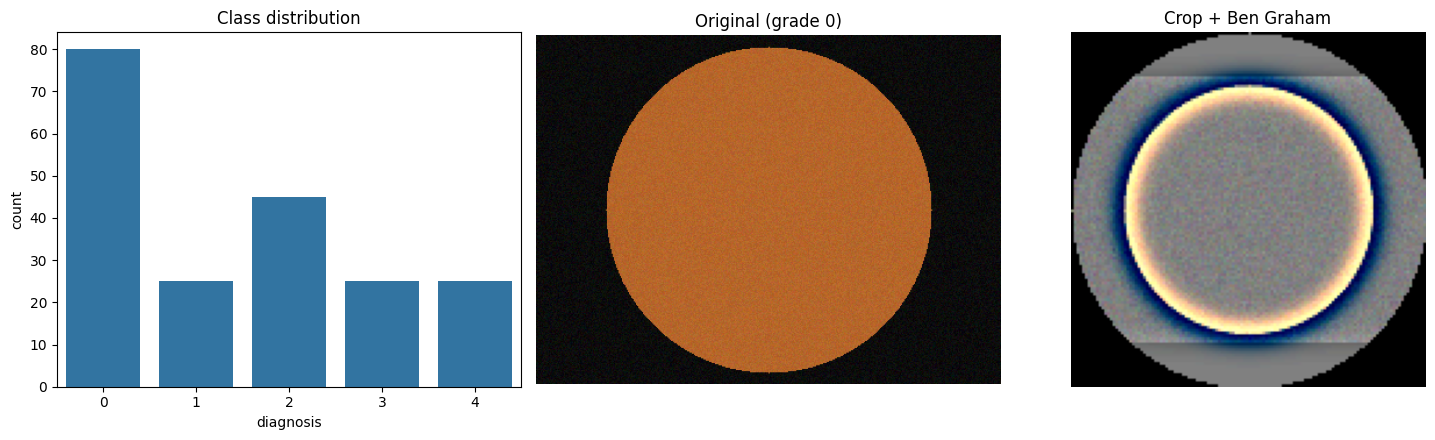

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
sns.countplot(x="diagnosis", data=df, ax=ax[0]); ax[0].set_title("Class distribution")
s = df.sample(1, random_state=1).iloc[0]; raw = cv2.imread(s.path)
ax[1].imshow(cv2.cvtColor(raw, cv2.COLOR_BGR2RGB)); ax[1].set_title(f"Original (grade {s.diagnosis})")
ax[2].imshow(preprocess_image(raw, IMG_SIZE)); ax[2].set_title("Crop + Ben Graham")
for a in ax[1:]: a.axis("off")
plt.tight_layout(); plt.show()

In [5]:
CACHE = f"cache_{IMG_SIZE}"; os.makedirs(CACHE, exist_ok=True)
def _prep(row):
    out = f"{CACHE}/{row.id_code}.png"
    if not os.path.exists(out):
        cv2.imwrite(out, cv2.cvtColor(preprocess_image(cv2.imread(row.path), IMG_SIZE), cv2.COLOR_RGB2BGR))
    return out
with ThreadPoolExecutor(max_workers=os.cpu_count() or 2) as ex:
    df["cache_path"] = list(tqdm(ex.map(_prep, df.itertuples()), total=len(df), desc="Preprocessing"))

Preprocessing:   0%|          | 0/200 [00:00<?, ?it/s]

In [6]:
tr_df, tmp = train_test_split(df, test_size=0.2, stratify=df.diagnosis, random_state=42)
va_df, te_df = train_test_split(tmp, test_size=0.5, stratify=tmp.diagnosis, random_state=42)
print(len(tr_df), len(va_df), len(te_df))

train_tf = A.Compose([
    A.HorizontalFlip(p=0.5), A.VerticalFlip(p=0.5),
    A.Rotate(limit=180, border_mode=cv2.BORDER_CONSTANT, p=0.8),
    A.RandomBrightnessContrast(0.15, 0.15, p=0.5),
    A.Normalize(mean=tuple(MEAN), std=tuple(STD)), ToTensorV2()])
eval_tf = A.Compose([A.Normalize(mean=tuple(MEAN), std=tuple(STD)), ToTensorV2()])

class DRData(Dataset):
    def __init__(self, d, tf): self.p, self.y, self.tf = d.cache_path.values, d.diagnosis.values, tf
    def __len__(self): return len(self.p)
    def __getitem__(self, i):
        img = cv2.cvtColor(cv2.imread(self.p[i]), cv2.COLOR_BGR2RGB)
        return self.tf(image=img)["image"], torch.tensor(self.y[i], dtype=torch.float32)

# Mild balancing: sample weight = 1/sqrt(class frequency)
cnt = tr_df.diagnosis.value_counts()
w = tr_df.diagnosis.map(lambda c: 1 / np.sqrt(cnt[c])).values
sampler = WeightedRandomSampler(w, num_samples=len(tr_df), replacement=True)
NW = 2 if DEVICE == "cuda" else 0
train_dl = DataLoader(DRData(tr_df, train_tf), BATCH, sampler=sampler, num_workers=NW, drop_last=True, pin_memory=True)
val_dl   = DataLoader(DRData(va_df, eval_tf), BATCH * 2, num_workers=NW)
test_dl  = DataLoader(DRData(te_df, eval_tf), BATCH * 2, num_workers=NW)

160 20 20


epoch 1/3:   0%|          | 0/10 [00:00<?, ?it/s]

ep 01 | train 1.014 | val MAE 1.411 | val QWK 0.0000 | 3s


epoch 2/3:   0%|          | 0/10 [00:00<?, ?it/s]

ep 02 | train 0.545 | val MAE 1.486 | val QWK 0.0000 | 1s


epoch 3/3:   0%|          | 0/10 [00:00<?, ?it/s]

ep 03 | train 0.338 | val MAE 0.992 | val QWK 0.4429 | 1s
best val QWK: 0.4429


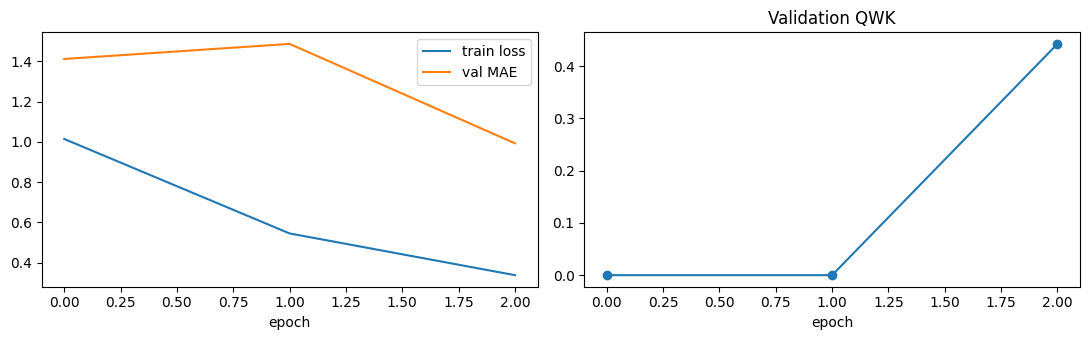

In [7]:
model = timm.create_model(ARCH, pretrained=PRETRAINED, num_classes=1).to(DEVICE)   # single output = ordinal regression
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-2)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=LR, epochs=EPOCHS, steps_per_epoch=len(train_dl))
crit = nn.SmoothL1Loss()
use_amp = DEVICE == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

def qwk(y, p): return cohen_kappa_score(y, p, weights="quadratic")

@torch.no_grad()
def predict(dl, tta=False):
    model.eval(); P, Y = [], []
    for x, y in dl:
        x = x.to(DEVICE)
        with torch.autocast(DEVICE, enabled=use_amp):
            p = model(x).squeeze(1).float()
            if tta:
                p = (p + model(x.flip(3)).squeeze(1).float() + model(x.flip(2)).squeeze(1).float()) / 3
        P.append(p.cpu().numpy()); Y.append(y.numpy())
    return np.concatenate(P), np.concatenate(Y).astype(int)

hist, best = {"loss": [], "val_loss": [], "val_qwk": []}, -1
for ep in range(EPOCHS):
    model.train(); tl, t0 = 0, time.time()
    for x, y in tqdm(train_dl, desc=f"epoch {ep+1}/{EPOCHS}", leave=False):
        x, y = x.to(DEVICE), y.to(DEVICE)
        opt.zero_grad(set_to_none=True)
        with torch.autocast(DEVICE, enabled=use_amp):
            loss = crit(model(x).squeeze(1).float(), y)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
        tl += loss.item()
    p, y = predict(val_dl)
    vl = float(np.mean(np.abs(p - y))); vq = qwk(y, np.clip(np.rint(p), 0, 4).astype(int))
    hist["loss"].append(tl / len(train_dl)); hist["val_loss"].append(vl); hist["val_qwk"].append(vq)
    if vq > best: best = vq; torch.save(model.state_dict(), "best.pt")
    print(f"ep {ep+1:02d} | train {hist['loss'][-1]:.3f} | val MAE {vl:.3f} | val QWK {vq:.4f} | {time.time()-t0:.0f}s")
print("best val QWK:", round(best, 4))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(hist["loss"], label="train loss"); ax[0].plot(hist["val_loss"], label="val MAE"); ax[0].legend(); ax[0].set_xlabel("epoch")
ax[1].plot(hist["val_qwk"], marker="o"); ax[1].set_title("Validation QWK"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.savefig("training_curves.png", dpi=120); plt.show()

thresholds: [-0.102  0.011  0.7    1.7  ] | val QWK default -> tuned: 0.4167 -> 0.9189

TEST  QWK = 0.9304 | accuracy = 0.7500
                   precision    recall  f1-score   support

        0 - No DR       1.00      1.00      1.00         8
         1 - Mild       1.00      0.33      0.50         3
     2 - Moderate       0.60      0.75      0.67         4
       3 - Severe       0.50      1.00      0.67         3
4 - Proliferative       0.00      0.00      0.00         2

         accuracy                           0.75        20
        macro avg       0.62      0.62      0.57        20
     weighted avg       0.74      0.75      0.71        20



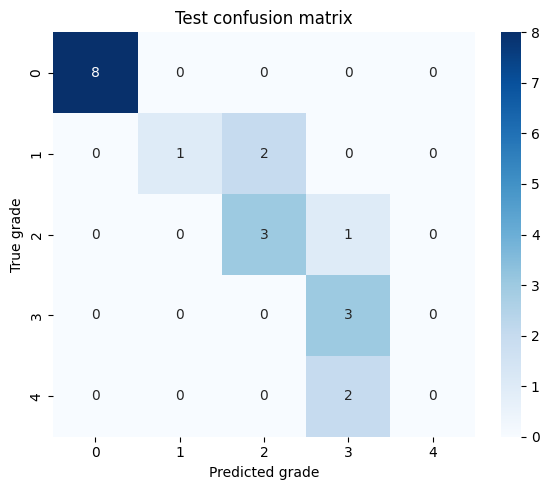

In [8]:
def optimize_thresholds(p, y, init=(0.5, 1.5, 2.5, 3.5)):
    t = list(init)
    for _ in range(3):
        for i in range(4):
            lo = t[i-1] + 0.01 if i else -1.0; hi = t[i+1] - 0.01 if i < 3 else 5.0
            cands = np.linspace(max(lo, t[i] - 0.6), min(hi, t[i] + 0.6), 49)
            t[i] = max(cands, key=lambda c: qwk(y, apply_thresholds(p, t[:i] + [c] + t[i+1:])))
    return t

model.load_state_dict(torch.load("best.pt", map_location=DEVICE))
pv, yv = predict(val_dl, tta=True)
THR = optimize_thresholds(pv, yv)
print("thresholds:", np.round(THR, 3), "| val QWK default -> tuned:",
      round(qwk(yv, np.clip(np.rint(pv), 0, 4).astype(int)), 4), "->", round(qwk(yv, apply_thresholds(pv, THR)), 4))

pt, yt = predict(test_dl, tta=True)
pred = apply_thresholds(pt, THR)
print(f"\nTEST  QWK = {qwk(yt, pred):.4f} | accuracy = {accuracy_score(yt, pred):.4f}")
print(classification_report(yt, pred, labels=range(5), target_names=GRADES, zero_division=0))
cm = confusion_matrix(yt, pred, labels=range(5))
plt.figure(figsize=(6, 5)); sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=range(5), yticklabels=range(5))
plt.xlabel("Predicted grade"); plt.ylabel("True grade"); plt.title("Test confusion matrix")
plt.tight_layout(); plt.savefig("confusion_matrix.png", dpi=120); plt.show()

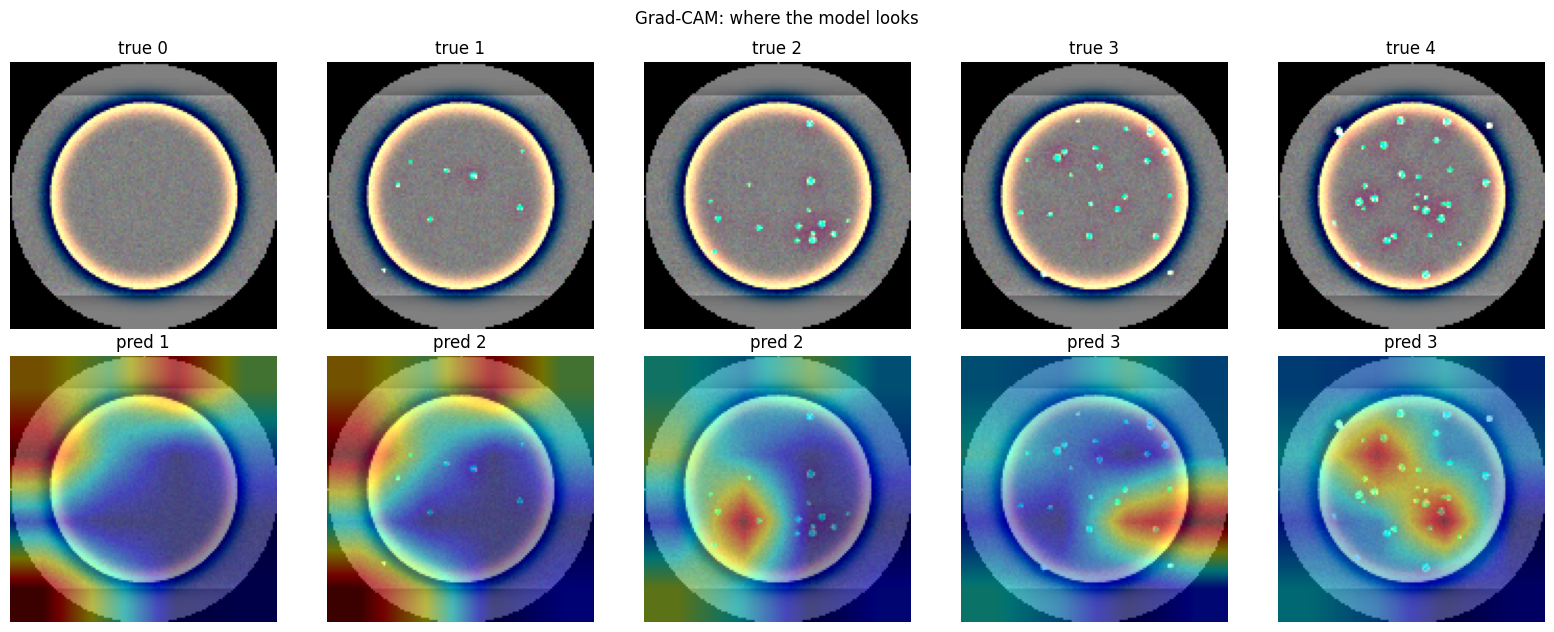

In [9]:
samples = te_df.groupby("diagnosis").head(1).sort_values("diagnosis")
fig, axs = plt.subplots(2, len(samples), figsize=(3.2 * len(samples), 6.4), squeeze=False)
for j, r in enumerate(samples.itertuples()):
    rgb = cv2.cvtColor(cv2.imread(r.cache_path), cv2.COLOR_BGR2RGB)
    cam, out = gradcam(model, to_tensor(rgb), DEVICE)
    axs[0, j].imshow(rgb); axs[0, j].set_title(f"true {r.diagnosis}"); axs[0, j].axis("off")
    axs[1, j].imshow(overlay(rgb, cam)); axs[1, j].set_title(f"pred {int(apply_thresholds(np.array([out]), THR)[0])}"); axs[1, j].axis("off")
plt.suptitle("Grad-CAM: where the model looks"); plt.tight_layout(); plt.savefig("gradcam.png", dpi=120); plt.show()

In [10]:
torch.save({"state_dict": model.state_dict(), "arch": ARCH, "img_size": IMG_SIZE, "thresholds": list(map(float, THR))}, "dr_model.pt")

open("app.py", "w").write('''
import cv2, numpy as np, torch, timm, gradio as gr
from dr_utils import *

dev = "cuda" if torch.cuda.is_available() else "cpu"
ck = torch.load("dr_model.pt", map_location=dev)
model = timm.create_model(ck["arch"], pretrained=False, num_classes=1).to(dev)
model.load_state_dict(ck["state_dict"]); model.eval()
SIZE, THR = ck["img_size"], ck["thresholds"]

def predict(rgb):
    bgr = cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR)
    img = preprocess_image(bgr, SIZE)
    cam, score = gradcam(model, to_tensor(img), dev)
    g = int(apply_thresholds(np.array([score]), THR)[0])
    return GRADES[g], overlay(img, cam)

demo = gr.Interface(predict, gr.Image(label="Retina fundus image"),
    [gr.Textbox(label="Predicted DR grade"), gr.Image(label="Grad-CAM")],
    title="Diabetic Retinopathy Grading",
    description="Educational demo - not a medical device. Upload a retinal fundus photo.")
if __name__ == "__main__":
    demo.launch()
''')
print("Saved dr_model.pt and app.py")

Saved dr_model.pt and app.py


In [11]:
# Optional: launch the demo (share=True gives a public link while the cell runs)
if not SYNTHETIC:
    import app
    app.demo.launch(share=True)